
# Module 3
## Lab 1: Gradient Descent

# Gradient Descent: A Quick Recap

We introduced **Gradient Descent** as a method to find the minimum of a loss function. It is the core optimization algorithm that powers a vast majority of **Machine Learning** and **Deep Learning** models.

---

### A Quick Recap of the Algorithm

The core idea of **Gradient Descent** is to iteratively take steps in the direction of the steepest descent of a function (our loss function) to find its minimum.

1. Start with a random initialization of the solution (model parameters or weights).
2. Incrementally change the solution by moving in the direction of the **negative gradient** of the loss function.
3. Repeat the previous step until some convergence criteria is met.

---

The key update equation for a weight or parameter ($w$) is:

$$
w_{k+1} \leftarrow w_k - \eta \nabla J
$$

Where:
- $w_k$ is the current weight.
- $\eta$ is the **learning rate**.
- $\nabla J$ is the **gradient of the loss function** $J$.


In this lab, we will discuss stochastic gradient descent, mini-batch gradient descent and batch gradient descent.


### Setting up the Environment and Data

First, let's import the necessary libraries and set a random seed for reproducibility.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
np.random.seed(42)

## Creating the Data

We'll generate some synthetic data that follows a **linear pattern**. Our true linear equation will be:

$$
y = 4 + 3x
$$

We will also add some **random noise** to the y values to simulate real-world data, which is rarely perfect.

Let's generate the data with:
- `y0 = 4` (intercept)
- `y1 = 3` (slope)

and add some noise to the data.


In [ ]:
# We are creating data based on the equation y = 4 + 3x + noise

X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1)

Here, np.random.rand(100, 1) creates 100 random numbers between 0 and 1. Multiplying by 2 scales this to be between 0 and 2. np.random.randn(100, 1) adds Gaussian noise (random fluctuations) to our y values.

Let's also plot the data we just created

Text(0, 0.5, 'y')

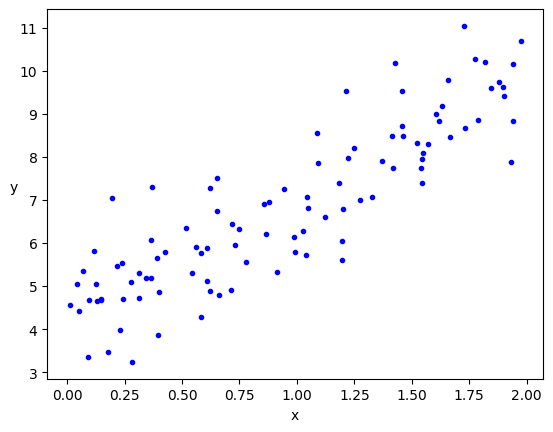

In [ ]:
plt.plot(X, y, 'b.')
plt.xlabel('x')
plt.ylabel('y', rotation=0)

Our goal is to use Gradient Descent to find the original parameters (intercept = 4, slope = 3) just by looking at this scattered data.

## The Cost Function for Linear Regression

Before we can optimize, we need to define how we measure error. For **Linear Regression**, we use the **Mean Squared Error (MSE)** cost function. It measures the average squared difference between the model's predictions and the actual values.

The equation for the MSE cost function $J$ is:

$$
J(\theta) = \frac{1}{2m}  \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right)^2
$$

Where:
- $m$ is the number of training examples.
- $\theta$ is our vector of model parameters (in our case, the intercept and the slope).
- $h_\theta(x^{(i)})$ is the prediction for the $i$-th example.
- $y^{(i)}$ is the true label for the $i$-th example.

The $\frac{1}{2}$ is included for convenience, as it simplifies the derivative calculation.


In [ ]:
def cal_cost(y_pred, X, y):
    """Calculate half mean squared error for the given parameters."""
    m = len(y)
    predictions = X.dot(y_pred)
    cost = (1 / (2 * m)) * np.sum(np.square(predictions - y))
    return float(cost)

## The Gradient of the Cost Function

To use **Gradient Descent**, we need the partial derivatives of the cost function with respect to each parameter \(\theta_j\).

The general form of the gradient for **Linear Regression** is:

$$
\frac{\partial J(\theta)}{\partial \theta_j} = \frac{1}{m} \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right) x_j^{(i)}
$$

For our problem with one feature \(x\) and an intercept, we have two parameters: \(\theta_0\) (intercept) and \(\theta_1\) (slope). The updates will be:

$$
\theta_0 := \theta_0 - \alpha \cdot \frac{1}{m} \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right)
$$

$$
\theta_1 := \theta_1 - \alpha \cdot \frac{1}{m} \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right) \cdot x_1^{(i)}
$$

This can be written in a compact, **vectorized form**:

$$
\nabla J(\theta) = \frac{1}{m} X^T (X\theta - y)
$$


### Variant 1: Batch Gradient Descent

**Batch Gradient Descent** is the simplest variant. In each step, it calculates the gradient using the **entire training dataset**.

**Pros:**
- The convergence path is smooth and stable because the gradient is a true average over all data.

**Cons:**
- It is very slow and computationally expensive for large datasets.


In [ ]:
def gradient_descent(X, y, y_pred, learning_rate=0.01, iterations=100):
    '''
    X = Matrix of X with added bias units
    y = Vector of Y
    y_pred = Vector of parameters (theta)
    learning_rate
    iterations = no of iterations

    Returns the final y_pred vector and array of cost history over no of iterations
    '''
    m = len(y)
    cost_history = np.zeros(iterations)
    y_pred_history = np.zeros((iterations, 2))

    for it in range(iterations):
        # Calculate prediction: prediction = X . theta
        prediction = np.dot(X, y_pred)

        # Update parameters: theta = theta - (1/m) * learning_rate * (X^T . (prediction - y))
        y_pred = y_pred - (1 / m) * learning_rate * (X.T.dot((prediction - y)))

        y_pred_history[it,:] = y_pred.T
        cost_history[it]  = cal_cost(y_pred, X, y)

    return y_pred, cost_history, y_pred_history

### Running Batch Gradient Descent

Let's run this for **1000 iterations** with a learning rate of **0.01**. We start with a random guess for our parameters (`y_pred`).

**Our model** is:
$$
y = \theta_0 + \theta_1 x
$$

**A crucial step:**
To handle the intercept term $\theta_0$ using matrix multiplication, we add a "dummy" feature $x_0 = 1$ to all our input samples. This is known as the **bias trick**.


In [ ]:
lr = 0.01
n_iter = 1000

y_pred = np.random.randn(2,1)
X_b = np.c_[np.ones((len(X), 1)), X]
y_pred, cost_history, y_pred_history = gradient_descent(X_b, y, y_pred, lr, n_iter)

print('y_pred[0]: {:0.3f}\ny_pred[1]: {:0.3f}'.format(y_pred[0][0], y_pred[1][0]))
print('Final error: {:0.3f}'.format(cost_history[-1]))

y_pred[0]: 3.903
y_pred[1]: 3.046
Final error: 0.418


The learned parameters (3.903, 3.046) are very close to our original true values (4, 3)!

### Visualizing the Loss

Let's plot the error at each iteration. This is our "descent down the mountain".

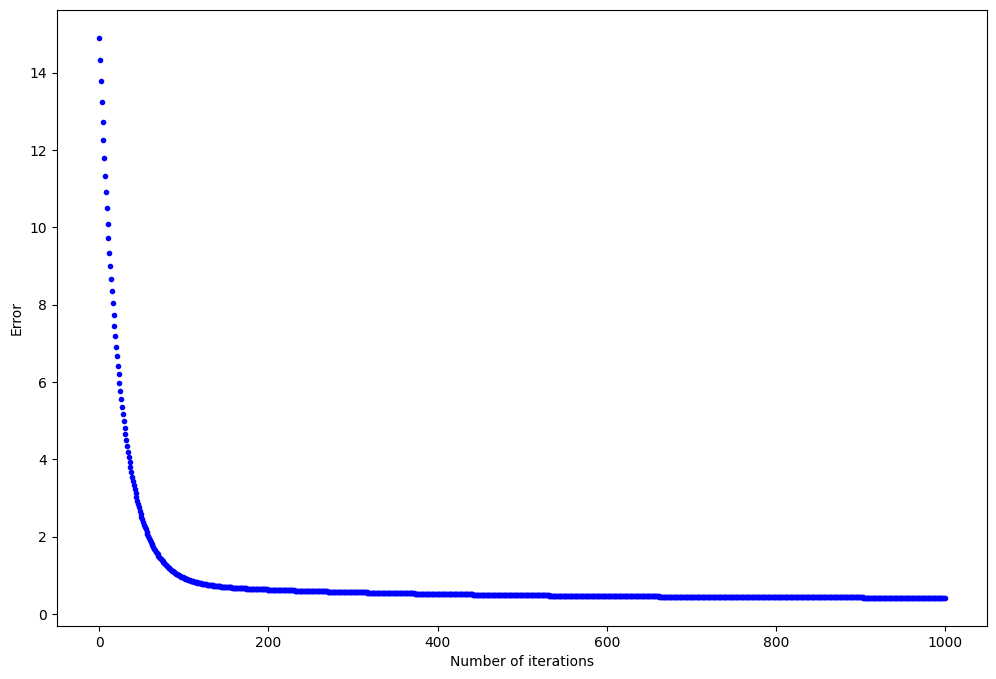

In [ ]:
fig, ax = plt.subplots(figsize=(12,8))

ax.set_ylabel('Error')
ax.set_xlabel('Number of iterations')

ax.plot(range(n_iter), cost_history, 'b.')

Zooming in on the first 200 iterations shows how the error drops rapidly at first and then slows down as it approaches the minimum.

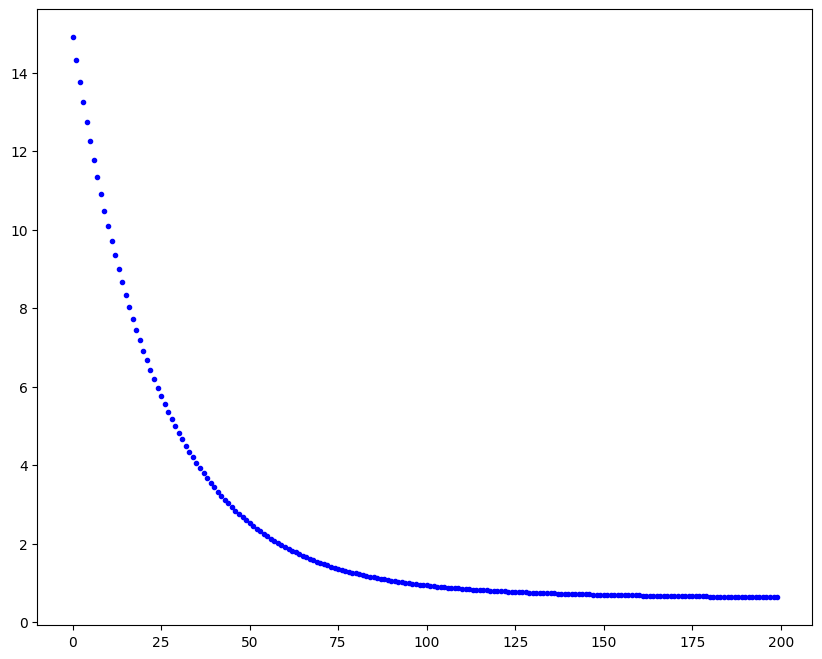

In [ ]:
fig,ax = plt.subplots(figsize=(10,8))
ax.plot(range(200), cost_history[:200], 'b.')

The smooth curve is characteristic of Batch Gradient Descent.

### Variant 2: Stochastic Gradient Descent (SGD)

**Batch GD** is inefficient for large datasets. **SGD** addresses this by taking a gradient step based on **only one randomly chosen training example at a time**.

**Pros:**
- Extremely fast per step.
- Can help escape shallow local minima due to its random nature.

**Cons:**
- The path to the minimum is very noisy and erratic.
- It never truly "settles" at the minimum but bounces around it.


In [ ]:
def stocashtic_gradient_descent(X, y, y_pred, learning_rate=0.01, iterations=10):
    """Perform stochastic gradient descent using one sample per update."""
    m = len(y)
    cost_history = np.zeros(iterations)
    for it in range(iterations):
        indices = np.random.permutation(m)
        for rand_ind in indices:
            X_i = X[rand_ind:rand_ind + 1, :]
            y_i = y[rand_ind:rand_ind + 1]
            prediction = X_i.dot(y_pred)
            y_pred = y_pred - learning_rate * X_i.T.dot(prediction - y_i)
        cost_history[it] = cal_cost(y_pred, X, y)
    return y_pred, cost_history

Let's run SGD. Note that it requires a much higher learning rate and fewer epochs (passes over the data) to converge.

In [ ]:
lr = 0.5
n_iter = 50
y_pred = np.random.randn(2, 1)
X_b = np.c_[np.ones((len(X), 1)), X]
y_pred, cost_history = stocashtic_gradient_descent(X_b, y, y_pred, lr, n_iter)

print('y_pred[0]: {:0.3f}\ny_pred[1]: {:0.3f}'.format(y_pred[0][0], y_pred[1][0]))
print('Final error: {:0.3f}'.format(cost_history[-1]))

y_pred[0]: 3.722
y_pred[1]: 2.648
Final error: 0.590


Again, the parameters are close to the true values, but notice the final error is higher and the parameters are slightly less accurate. This is due to the noisy nature of SGD.


### Visualizing the Loss

The loss curve for SGD is much more erratic.

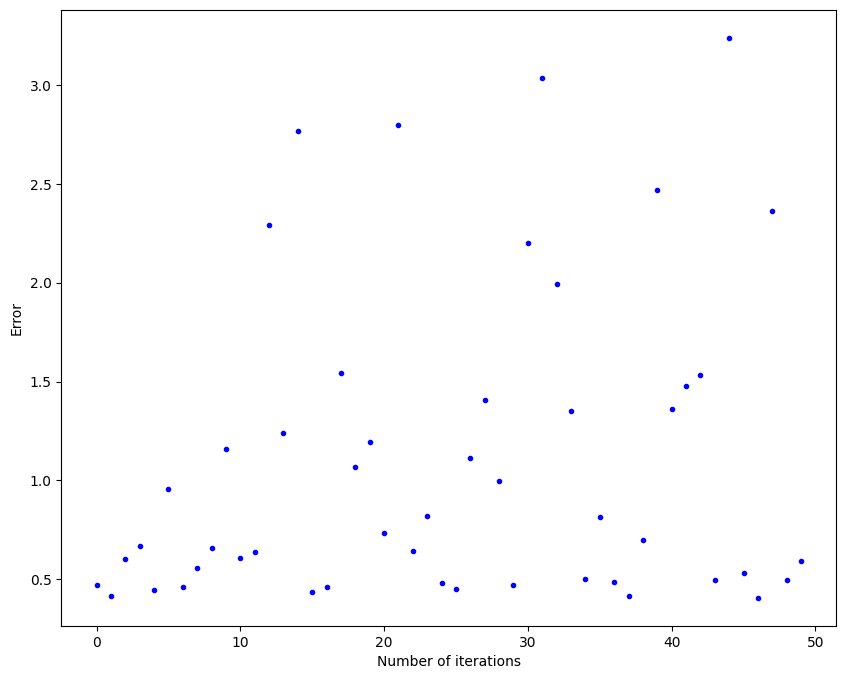

In [ ]:
fig, ax = plt.subplots(figsize=(10,8))

ax.set_ylabel('Error')
ax.set_xlabel('Number of iterations')
y_pred = np.random.randn(2,1)

ax.plot(range(n_iter), cost_history, 'b.')

### Variant 3: Mini-Batch Gradient Descent

**Mini-Batch GD** is the happy medium. It computes the gradient on a small, random subset of the data called a **mini-batch**.

**Pros:**
- A good balance between the stability of Batch GD and the speed of SGD.
- Allows for vectorized implementation, making it very efficient on modern hardware (like GPUs).

**Cons:**
- Introduces a new hyperparameter: the `batch_size`.

This is the **most common variant** used in deep learning today.


In [ ]:
def minibatch_gradient_descent(X, y, y_pred, learning_rate=0.01, iterations=10, batch_size=20):
    """Perform mini-batch gradient descent using batches of training samples."""
    m = len(y)
    cost_history = np.zeros(iterations)
    for it in range(iterations):
        indices = np.random.permutation(m)
        X_shuffled, y_shuffled = X[indices], y[indices]
        for i in range(0, m, batch_size):
            X_i = X_shuffled[i:i + batch_size]
            y_i = y_shuffled[i:i + batch_size]
            X_i_b = np.c_[np.ones((len(X_i), 1)), X_i]
            prediction = X_i_b.dot(y_pred)
            batch_m = len(y_i)
            y_pred = y_pred - (learning_rate / batch_m) * X_i_b.T.dot(prediction - y_i)
        X_b_full = np.c_[np.ones((m, 1)), X]
        cost_history[it] = cal_cost(y_pred, X_b_full, y)
    return y_pred, cost_history

Let's run it.

In [ ]:
lr = 0.1
n_iter = 200
y_pred = np.random.randn(2,1)
y_pred, cost_history = minibatch_gradient_descent(X, y, y_pred, lr, n_iter)

print('y_pred[0]: {:0.3f}\ny_pred[1]: {:0.3f}'.format(y_pred[0][0], y_pred[1][0]))
print('Final error: {:0.3f}'.format(cost_history[-1]))

y_pred[0]: 4.213
y_pred[1]: 2.764
Final error: 0.403


### Visualizing the Loss

The loss curve is less noisy than SGD but not as smooth as Batch GD.

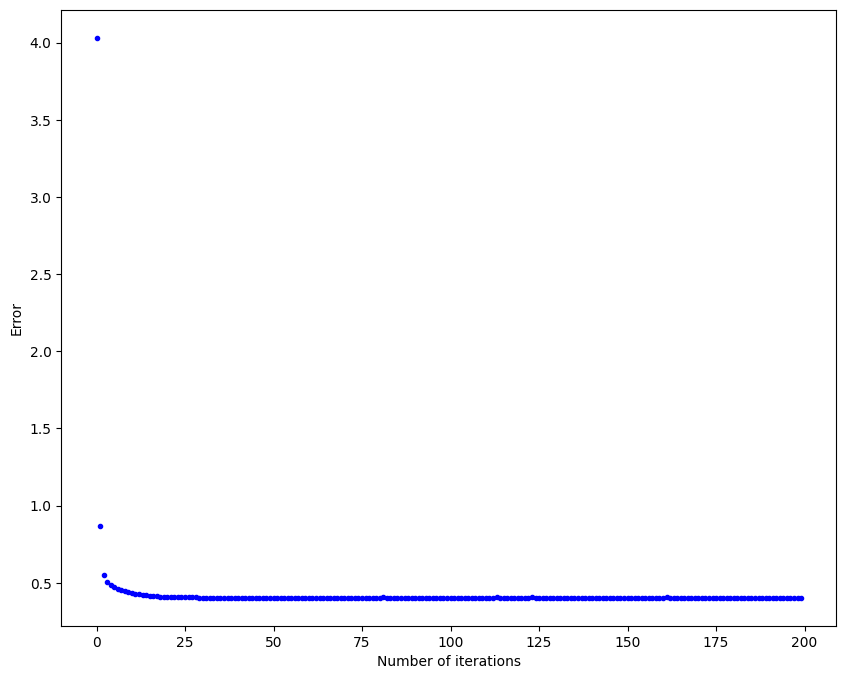

In [ ]:
fig, ax = plt.subplots(figsize=(10,8))

ax.set_ylabel('Error')
ax.set_xlabel('Number of iterations')
y_pred = np.random.randn(2,1)

ax.plot(range(n_iter), cost_history, 'b.')

### Visual Comparison of the Learned Models

Let's re-run all three algorithms and plot their final learned lines on the original data. This will give us a better intuition for how they perform.

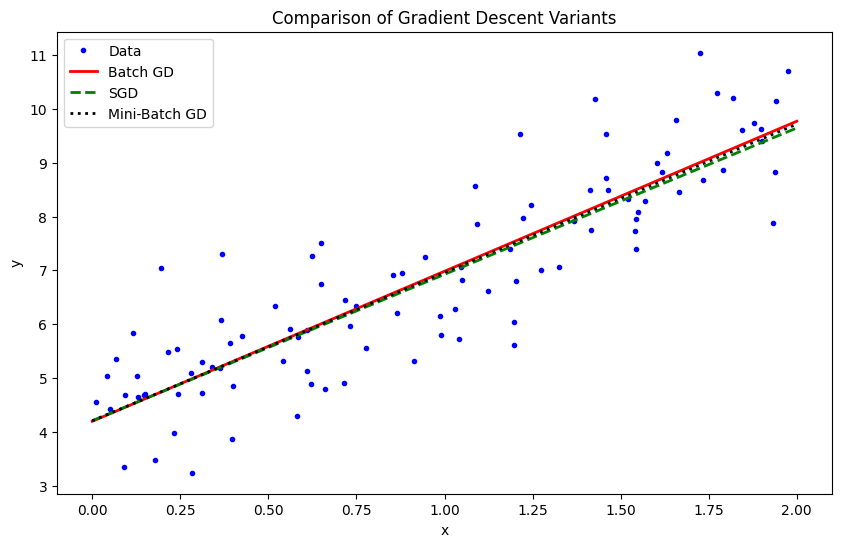

In [ ]:
# Rerun all three for comparison
# Batch
lr_batch = 0.1
n_iter_batch = 200
y_pred_batch_final, _, _ = gradient_descent(X_b, y, np.random.randn(2,1), lr_batch, n_iter_batch)

# SGD
lr_sgd = 0.05
n_iter_sgd = 200
y_pred_sgd_final, _ = stocashtic_gradient_descent(X_b, y, np.random.randn(2,1), lr_sgd, n_iter_sgd)

# Mini-Batch
lr_mini = 0.1
n_iter_mini = 200
y_pred_mini_final, _ = minibatch_gradient_descent(X, y, np.random.randn(2,1), lr_mini, n_iter_mini)


# Plotting
plt.figure(figsize=(10, 6))
plt.plot(X, y, 'b.', label='Data')
# Create a set of X values for plotting the lines
X_new = np.array([[0], [2]])
X_new_b = np.c_[np.ones((2, 1)), X_new]
# Get predictions for the lines
y_predict_batch = X_new_b.dot(y_pred_batch_final)
y_predict_sgd = X_new_b.dot(y_pred_sgd_final)
y_predict_mini = X_new_b.dot(y_pred_mini_final)

plt.plot(X_new, y_predict_batch, 'r-', linewidth=2, label='Batch GD')
plt.plot(X_new, y_predict_sgd, 'g--', linewidth=2, label='SGD')
plt.plot(X_new, y_predict_mini, 'k:', linewidth=2, label='Mini-Batch GD')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Comparison of Gradient Descent Variants')
plt.legend()
plt.show()

As you can see, all three methods find a very good fit to the data. While their training dynamics (the loss curves) are very different, they all achieve the same goal.

### Things to Try Out

1. **Change batch size in mini-batch gradient descent:**
   Try a small size (e.g., `2`) and a large size (e.g., `80`). How does the loss curve change? What happens when the batch size equals the total number of samples?

2. **Test on real datasets:**
   Use a dataset from `sklearn.datasets`, like the **Boston Housing** or **Diabetes** datasets, and see how each variant performs.

3. **Compare learning rates:**
   Test the effects of changing the learning rate. Try a very high and a very low learning rate for each of the three variants. Which one is most sensitive to the learning rate?

4. **Implement a learning rate schedule for SGD:**
   Instead of a fixed learning rate, make it decrease over time (e.g., `lr = initial_lr / (epoch + 1)`). How does this affect the final error and the stability of the loss curve?


## **Additional Critical Thinking Question**



**Which of the following is TRUE, given the optimal learning rate?**

 (i) Batch gradient descent is always guaranteed to converge to the global optimum of a loss function.

 (ii) Stochastic gradient descent is always guaranteed to converge to the global optimum of a loss function.

 (iii) For convex loss functions (i.e. with a bowl shape), batch gradient descent is guaranteed to eventually converge to the global optimum while stochastic gradient descent is not.

 (iv) For convex loss functions (i.e. with a bowl shape), stochastic gradient descent is guaranteed to eventually converge to the global optimum while batch gradient descent is not.

 (v) For convex loss functions (i.e. with a bowl shape), both stochastic gradient descent and batch gradient descent will eventually converge to the global optimum.

 (vi) For convex loss functions (i.e. with a bowl shape), neither stochastic gradient descent nor batch gradient descent are guaranteed to converge to the global optimum.

### Answer



The correct statement is (iii).

**Explanation:**

* A convex loss function has a single minimum, which is the global minimum (like a perfect bowl).

* Batch Gradient Descent calculates the true gradient of the entire dataset. With a suitable learning rate, it will take determined, non-random steps directly towards the minimum. It is therefore guaranteed to converge to the global optimum of a convex function.

* Stochastic Gradient Descent uses a single random point to estimate the gradient. This estimate is noisy and does not point directly at the minimum. Because of this randomness, SGD will not converge to the exact minimum point but will instead perpetually bounce around in the vicinity of the minimum. To make it converge, one typically has to use a learning rate schedule that slowly decreases the learning rate to zero.

* Statements (i) and (ii) are too strong; they don't specify the type of loss function. For a non-convex function (with many local minima), neither is guaranteed to find the global optimum. They might get stuck in a local minimum.

* **Therefore**, for a convex problem, Batch GD is guaranteed to find the optimum, while standard SGD is not guaranteed to land precisely on it.

## Completing the “Things to Try Out” Exercises

The following cells complete all four exercises in the order given in the original notebook. The experiments use the corrected implementations above and report the values produced by execution.

### Exercise 1: Effect of Mini-Batch Size

**Aim:** Compare mini-batch sizes of 2, 80, and 100 (the complete dataset contains 100 samples).

**Observation:** A small batch produces more frequent, noisier updates. A larger batch produces a more stable loss curve. When `batch_size = 100`, each update uses the complete dataset, so Mini-Batch GD behaves like Batch GD in terms of the gradient calculation.

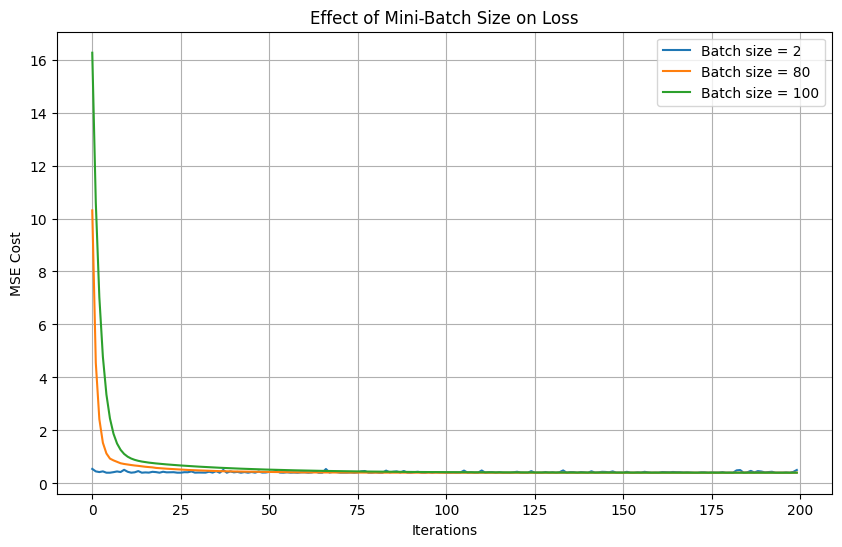

Batch size 2: theta0=4.012, theta1=2.529, final cost=0.5060
Batch size 80: theta0=4.190, theta1=2.720, final cost=0.4063
Batch size 100: theta0=4.147, theta1=2.831, final cost=0.4040


In [ ]:
batch_sizes = [2, 80, 100]
batch_size_results = {}

plt.figure(figsize=(10, 6))
for batch_size in batch_sizes:
    np.random.seed(123)
    theta_final, costs = minibatch_gradient_descent(
        X, y, np.random.randn(2, 1),
        learning_rate=0.1, iterations=200, batch_size=batch_size
    )
    batch_size_results[batch_size] = (theta_final, costs)
    plt.plot(costs, label=f'Batch size = {batch_size}')

plt.xlabel('Iterations')
plt.ylabel('MSE Cost')
plt.title('Effect of Mini-Batch Size on Loss')
plt.legend()
plt.grid(True)
plt.show()

for batch_size, (theta_final, costs) in batch_size_results.items():
    print(f'Batch size {batch_size}: theta0={theta_final[0,0]:.3f}, '
          f'theta1={theta_final[1,0]:.3f}, final cost={costs[-1]:.4f}')

### Exercise 2: Test on a Real Dataset

**Aim:** Apply the three gradient descent variants to a real dataset from `sklearn.datasets`.

**Dataset:** Diabetes dataset (442 samples). To keep the experiment compatible with the notebook's single-feature, two-parameter implementation, the BMI feature is selected. The feature and target are standardized for stable optimization.

**Observation:** The three methods learn similar linear relationships. Small differences in final costs arise from their different update procedures and random sample ordering.

In [ ]:
from sklearn.datasets import load_diabetes

diabetes = load_diabetes()
X_real = diabetes.data[:, [2]]  # BMI feature
y_real = diabetes.target.reshape(-1, 1)

# Standardize the selected feature and target.
X_real = (X_real - X_real.mean()) / X_real.std()
y_real = (y_real - y_real.mean()) / y_real.std()
X_real_b = np.c_[np.ones((len(X_real), 1)), X_real]

np.random.seed(7)
theta_batch_real, cost_batch_real, _ = gradient_descent(
    X_real_b, y_real, np.random.randn(2, 1), 0.1, 1000
)

np.random.seed(7)
theta_sgd_real, cost_sgd_real = stocashtic_gradient_descent(
    X_real_b, y_real, np.random.randn(2, 1), 0.01, 50
)

np.random.seed(7)
theta_mini_real, cost_mini_real = minibatch_gradient_descent(
    X_real, y_real, np.random.randn(2, 1), 0.1, 200, 20
)

print('Diabetes dataset samples:', len(X_real))
print('Feature used: BMI')
print(f'Batch GD:      theta0={theta_batch_real[0,0]:.3f}, theta1={theta_batch_real[1,0]:.3f}, cost={cost_batch_real[-1]:.4f}')
print(f'SGD:           theta0={theta_sgd_real[0,0]:.3f}, theta1={theta_sgd_real[1,0]:.3f}, cost={cost_sgd_real[-1]:.4f}')
print(f'Mini-Batch GD: theta0={theta_mini_real[0,0]:.3f}, theta1={theta_mini_real[1,0]:.3f}, cost={cost_mini_real[-1]:.4f}')

Diabetes dataset samples: 442
Feature used: BMI
Batch GD:      theta0=-0.000, theta1=0.586, cost=0.3280
SGD:           theta0=0.026, theta1=0.646, cost=0.3302
Mini-Batch GD: theta0=-0.010, theta1=0.644, cost=0.3298


### Exercise 3: Compare Learning Rates

**Aim:** Compare low, suitable, and excessively high learning rates for Batch GD, SGD, and Mini-Batch GD.

**Procedure:** Each method is tested with learning rates `0.0001`, `0.01`, `0.1`, and `1.0`. The same synthetic dataset is used. Batch GD and Mini-Batch GD run for 200 iterations/epochs, while SGD runs for 50 epochs (one shuffled pass through the 100 samples per epoch).

**Observation:** A very low learning rate causes slow learning. Suitable rates reduce the cost effectively. An excessively high rate makes the updates overshoot the minimum and can cause divergence. The sensitivity differs between methods because their gradients are calculated from different amounts of data and their update frequencies differ. The printed costs are the actual results from this run.

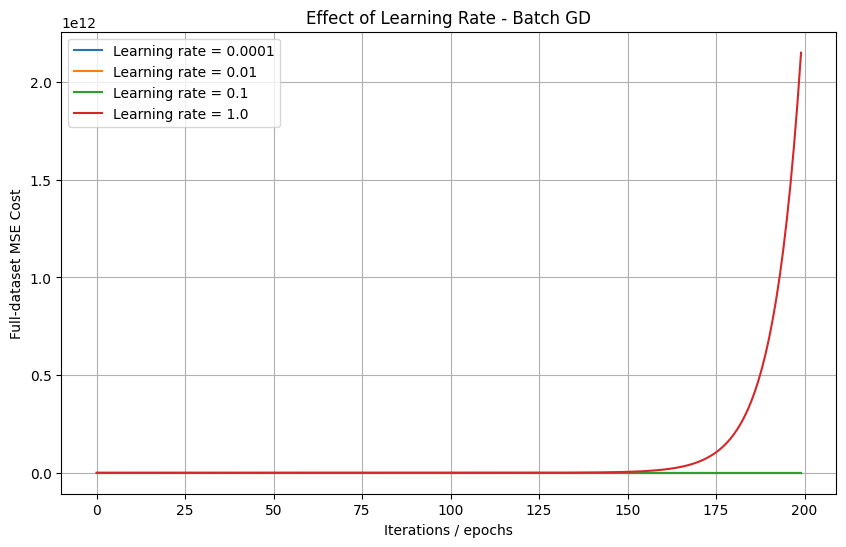

Batch GD, learning rate 0.0001: final cost=23.0644, theta0=0.134, theta1=0.145
Batch GD, learning rate 0.01: final cost=0.4848, theta0=3.458, theta1=3.339
Batch GD, learning rate 0.1: final cost=0.4035, theta0=4.183, theta1=2.799
Batch GD, learning rate 1.0: final cost=2151064130315.5957, theta0=-955323.482, theta1=-1081975.155


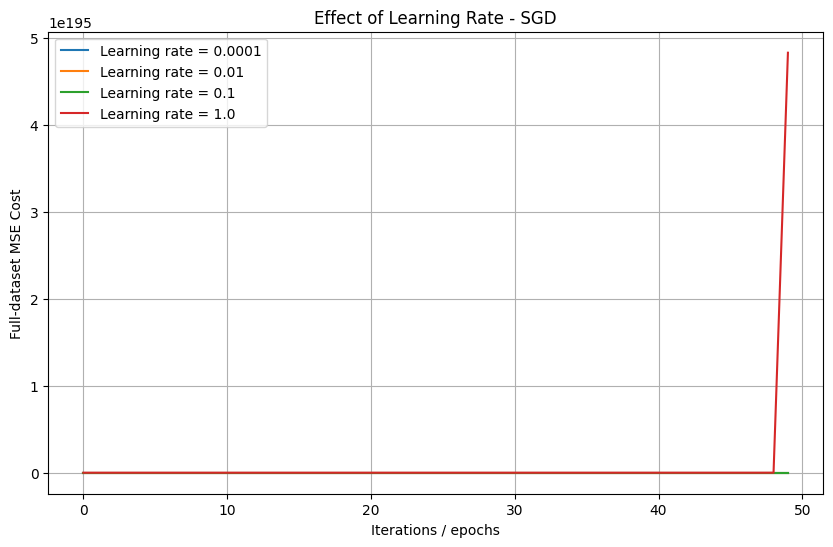

SGD, learning rate 0.0001: final cost=3.6291, theta0=2.155, theta1=2.278
SGD, learning rate 0.01: final cost=0.4067, theta0=4.180, theta1=2.725
SGD, learning rate 0.1: final cost=0.4343, theta0=4.126, theta1=2.618
SGD, learning rate 1.0: final cost=4828355900186225222501742929013320524139333714588733478223962562698360479925026548141234095033336140324666570195739427661853260255887238215487074171830061564412419321208126616698314319312814342144.0000, theta0=55491751936250892156000586402841794833811090414147319014362003709925522621216134371078674707382272.000, theta1=42076775860371234727296466672668386338663763014906581795250761153830427074372468680351121284268032.000


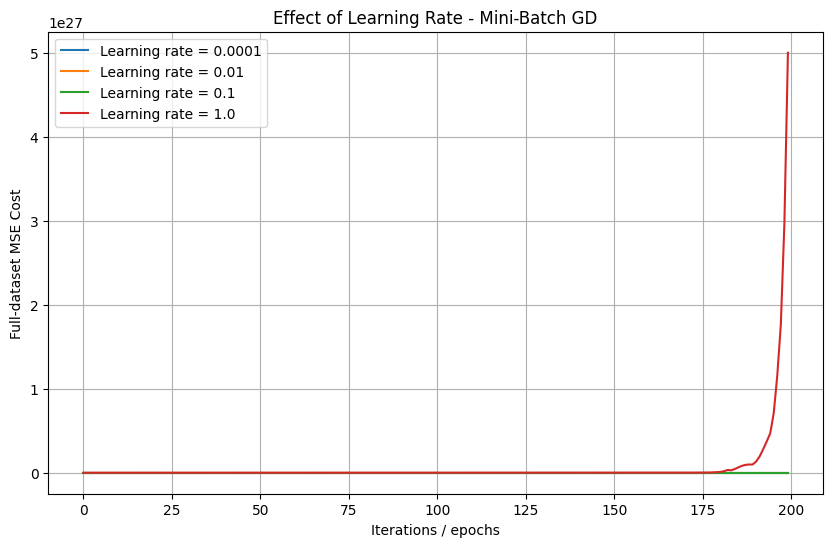

Mini-Batch GD, learning rate 0.0001: final cost=16.7255, theta0=0.618, theta1=0.666
Mini-Batch GD, learning rate 0.01: final cost=0.4083, theta0=4.033, theta1=2.931
Mini-Batch GD, learning rate 0.1: final cost=0.4034, theta0=4.221, theta1=2.779
Mini-Batch GD, learning rate 1.0: final cost=5006668874497382309664129024.0000, theta0=-42495500548571.875, theta1=-55354602971974.570


In [ ]:
learning_rates = [0.0001, 0.01, 0.1, 1.0]
learning_rate_results = {}

for method in ['Batch GD', 'SGD', 'Mini-Batch GD']:
    learning_rate_results[method] = {}
    plt.figure(figsize=(10, 6))

    for rate in learning_rates:
        np.random.seed(321)
        initial_theta = np.zeros((2, 1))

        if method == 'Batch GD':
            theta_final, costs, _ = gradient_descent(
                X_b, y, initial_theta.copy(),
                learning_rate=rate, iterations=200
            )
        elif method == 'SGD':
            theta_final, costs = stocashtic_gradient_descent(
                X_b, y, initial_theta.copy(),
                learning_rate=rate, iterations=50
            )
        else:
            theta_final, costs = minibatch_gradient_descent(
                X, y, initial_theta.copy(),
                learning_rate=rate, iterations=200, batch_size=20
            )

        learning_rate_results[method][rate] = (theta_final, costs)
        plt.plot(costs, label=f'Learning rate = {rate}')

    plt.xlabel('Iterations / epochs')
    plt.ylabel('Full-dataset MSE Cost')
    plt.title(f'Effect of Learning Rate - {method}')
    plt.legend()
    plt.grid(True)
    plt.show()

    for rate, (theta_final, costs) in learning_rate_results[method].items():
        print(f'{method}, learning rate {rate}: '
              f'final cost={costs[-1]:.4f}, '
              f'theta0={theta_final[0,0]:.3f}, '
              f'theta1={theta_final[1,0]:.3f}')


### Exercise 4: Implement a Learning Rate Schedule for SGD

**Aim:** Reduce the learning rate over epochs using `lr = initial_lr / (epoch + 1)`.

**Observation:** The larger initial updates help SGD make progress quickly. Gradually reducing the learning rate makes later updates smaller and the loss more stable near the minimum. The final cost depends on the initial learning rate and number of epochs.

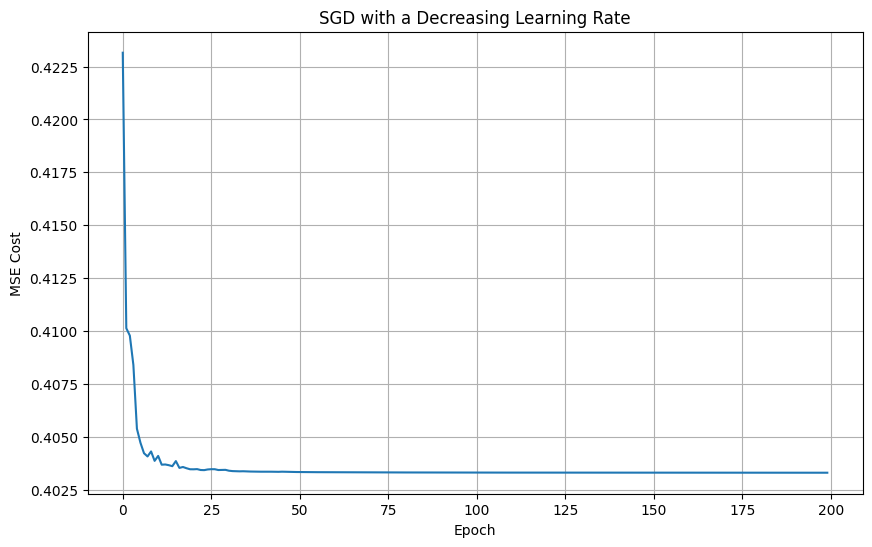

Final parameters: theta0=4.211, theta1=2.775
Final cost: 0.4033


In [ ]:
def sgd_with_learning_rate_schedule(X, y, theta, initial_lr=0.05, epochs=200):
    m = len(y)
    cost_history = np.zeros(epochs)

    for epoch in range(epochs):
        learning_rate = initial_lr / (epoch + 1)
        for index in np.random.permutation(m):
            X_i = X[index:index + 1]
            y_i = y[index:index + 1]
            prediction = X_i.dot(theta)
            theta = theta - learning_rate * X_i.T.dot(prediction - y_i)

        cost_history[epoch] = cal_cost(theta, X, y)

    return theta, cost_history

np.random.seed(42)
theta_scheduled, scheduled_cost = sgd_with_learning_rate_schedule(
    X_b, y, np.random.randn(2, 1), initial_lr=0.05, epochs=200
)

plt.figure(figsize=(10, 6))
plt.plot(scheduled_cost)
plt.xlabel('Epoch')
plt.ylabel('MSE Cost')
plt.title('SGD with a Decreasing Learning Rate')
plt.grid(True)
plt.show()

print(f'Final parameters: theta0={theta_scheduled[0,0]:.3f}, '
      f'theta1={theta_scheduled[1,0]:.3f}')
print(f'Final cost: {scheduled_cost[-1]:.4f}')

**Overall Exercise Result:** Mini-batch size controls the balance between update noise and computational efficiency. Real-dataset testing demonstrates that the methods can be applied beyond synthetic data. Learning-rate experiments across Batch GD, SGD, and Mini-Batch GD show that all methods need an appropriate learning rate; excessively high values can cause divergence, while very low values slow convergence. A decreasing learning-rate schedule can improve the stability of SGD.

## Additional Critical Thinking Question – Answer Clarification

**Expected answer according to the notebook's stated fixed-learning-rate SGD explanation: (iii).**

Batch Gradient Descent uses the full-dataset gradient and, for a suitable learning rate on a convex objective, can converge to the global minimum. Standard SGD with a constant learning rate generally fluctuates around the minimum because each update is based on one sample.

**Important qualification:** The statement that SGD is not guaranteed to converge exactly applies to the standard constant-learning-rate version described in this lab. SGD with an appropriate decreasing learning-rate schedule can also converge under suitable mathematical conditions. Therefore, the wording of the question is simplified; option (iii) is the intended answer in the context of the notebook.